# Phase 6Q-1 (Qwen3-8B): baseline, seeded rerun

**Goal:** the control for the three KiL pipelines (shallow, semi-deep, deep), all on Qwen3-8B. This is the **seeded rerun** (H14): 07Q gave the user simulator seed = trial number, so this baseline is run again with the same 8 seeds. Then every system in 10Q differs only in the agent, not in the seeds. The first run (v2, no seeds) is kept as `results_qwen_base_noseed` and used only for a seed check.

**Result (details in cell 15):** pass^1 0.147 [0.08, 0.22], pass^8 0.000; always / sometimes / never pass 0 / 18 / 32. The same as the unseeded run (Δpass^1 −0.003, not significant at any k): adding seeds did not change the baseline.

**Pipeline (example: cancel a flight):**

```
user input → [prompt = prose policy only, as τ-bench ships it] → Qwen3-8B → action or reply
```

No policy graph, no LoRA, no validator.

**Spec check (brief → this notebook):**

| Brief says (quote) | This notebook | Same? |
|---|---|---|
| "Stock agent, prose policy in prompt": "Baseline as the benchmark ships" | τ-bench's own tool-calling agent and `wiki.md`, nothing added (cells 8 and 10 check that the shallow checklist is not in the prompt: 0 of 400) | yes |
| "Run each task at least 8 times with different simulator seeds" | 50 tasks × 8 trials; trial t gives seed t to every user-simulator call (`qwen_run.py`, the same runner and seeds as 07Q). Cell 8: Gemini accepts the seed, the same seed repeats a reply, another seed gives another reply. 2,845 seeded user calls logged | yes, with a caveat: Gemini calls its seed "best effort" |
| "Report means with confidence intervals" | pass^k with 95% bootstrap CI; paired Δ with 95% CI (cell 12) | yes |
| "Policy-violation rate, split into three types" / "by turn position" / "on tasks that still pass" | the same violation cell as 07Q (cell 13) | yes (types 2 and 3 are proxies) |
| Office hour: Qwen, not Gemini | agent = Qwen3-8B | yes |

**Seed check:** cell 12 compares this run with the unseeded run, paired over tasks. Result: not significant at any k (Δpass^1 −0.003 [−0.048, +0.045]), so the seeds did not change the result.

**Who plays which role:**

| Role | Model | Settings |
|---|---|---|
| Agent (the airline agent being tested) | **Qwen3-8B** on vLLM 0.34.0 | thinking off, temperature 0.0, hermes tool parser |
| Customer (the user simulator) | **Gemini** `gemini-3.1-flash-lite` | seed = trial number; temperature 1.0 (`deep_run.py`, shown in cell 3) |

**Run first:** 04, 06G (`policy_checker.py`, `violations.py`), 07Q cell 4 (`qwen_run.py`). **Runtime:** L4 or larger (24k context and `--max-num-seqs 8` on an L4, both recorded). **Time and cost (this run, L4):** about 2.5 h, about $1 for the Gemini user simulator. Trial 1 ran in two parts (16 + 34 tasks) after a Colab stop; see the run note in cell 15.

**Order:** 1 → 14 in order (not "Run all"). Cell 4 renames the unseeded run once; it never deletes anything. Run 05Q before 06Q: 06Q compares with this run.

**Only re-analysing saved results?** Run cells 1, 2, 3, 10–14. No GPU server needed.

**Output:** `results_qwen_base/trial_1..8/` (dialogues, `calls.jsonl`, `seeds.log`), plus `results_qwen_base_config.json`, `_vllm.json`, `_passk.csv`, `_vs_noseed.csv`, `_violations.json`, `_consistency.json`. Safe to stop: finished tasks are skipped.

In [2]:
# Why: results and code live on Google Drive, so they survive when the Colab runtime resets.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Why: make sure every package the Qwen notebooks need is present, checked one by one. Colab images
# sometimes ship vLLM without litellm, so a single vLLM check lets cell 4 die on `import litellm`.
# Only missing packages get installed; vLLM takes a few minutes, the rest are quick.
import importlib, importlib.util, site, subprocess
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
PKGS = [("tau_bench", f"-e {ROOT}"), ("litellm", "litellm"), ("vllm", "vllm"),
        ("peft", "peft"), ("mcp", "mcp")]

def have(mod):
    importlib.invalidate_caches()
    try:
        site.main()            # pick up what pip just added to this running kernel
    except Exception:
        pass
    try:
        return importlib.util.find_spec(mod) is not None
    except Exception:
        return False

def pip_install(spec):
    r = subprocess.run(f"pip install -q {spec}", shell=True, capture_output=True, text=True, cwd=ROOT)
    return [l for l in (r.stdout + r.stderr).splitlines()
            if "error" in l.lower() and "protobuf" not in l.lower()]

rows, errors = [], []
for mod, spec in PKGS:
    if have(mod):
        rows.append({"package": mod, "action": "already there"})
        continue
    errors += pip_install(spec)
    if mod == "vllm":
        subprocess.run("pip uninstall -y -q torchao", shell=True, capture_output=True)  # clashes with vLLM
    rows.append({"package": mod, "action": "installed" if have(mod) else "❌ still missing"})

display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
if errors:
    print("\n".join(errors[-5:]))

package,action
tau_bench,installed
litellm,already there
vllm,already there
peft,already there
mcp,already there


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


In [7]:
# Why: every arm must use the same frozen settings, or the comparison is not fair. The agent
# settings come from settings_deep.py and settings_gemini.py. The agent temperature is set here
# once and used by cells 6 and 7; an assert stops the run if it ever drifts from settings_gemini.
# This is the seeded rerun (H14): trial t gives seed t to every user-simulator call, as in 07Q, so all
# five systems share the same 8 seeds. OLD is the first run (no seeds): kept, read only, for a seed check.
# The Gemini key comes from Colab Secrets and is never printed.
import os, sys, json, time, glob, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT)
os.chdir(ROOT)
NEED = ["settings_gemini.py", "settings_deep.py", "deep_run.py", "qwen_run.py", "policy_checker.py",
        "violations.py", "airline_policy_graph.json", "passk.py"]
missing = [f for f in NEED if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 04 and 06G first; qwen_run.py is written by 07Q cell 4"

importlib.invalidate_caches()
import settings_gemini, settings_deep, passk
importlib.reload(settings_gemini); importlib.reload(settings_deep)
from settings_gemini import (MODEL as USER_MODEL, ENV, N_TASKS, N_TRIALS,
                             TEMPERATURE, CONCURRENCY, PRICE_IN, PRICE_OUT)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, AGENT_THINKING

AGENT_TEMP = 0.0                                    # one source of truth for cells 6 and 7
SEEDS = True        # simulator seed = trial number (the same as 07Q)
VALIDATOR = False                                 # 06G's checker blocks illegal write calls
assert TEMPERATURE == AGENT_TEMP, f"settings_gemini.TEMPERATURE is {TEMPERATURE}, expected {AGENT_TEMP}"
TEMP_LINES = [f"line {i}: {l.strip()[:90]}" for i, l in enumerate(open("deep_run.py"), 1) if "temperature" in l.lower()]
USER_TEMP = "see deep_run.py lines below"
ARM, OUT = "base", "results_qwen_base"
OLD = f"{OUT}_noseed"                              # the first run, renamed by cell 4 (never deleted)
BASE_OUT = "results_qwen_base"
ARMS = [(f"qwen {ARM} (05Q)", OUT, "#257de0"),         # name, folder, color (H7); this arm first
        ("qwen base, no seed (05Q v2)", OLD, "#9e9e9e")]  # the first run, for the seed check only
COMPARE = [("base no seed", OLD, "vs_noseed")]       # seed check: should be n.s.

warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)
from google.colab import userdata
os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"

def show(df):
    display(df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

_TAB = {}
def tab_of(folder, reload=False):
    # read the saved dialogues off Drive once; cells 10-14 share the copy
    import passk
    if reload or folder not in _TAB:
        importlib.reload(passk)
        _TAB[folder] = passk.table(f"{ROOT}/{folder}")
    return _TAB[folder]

def has_checklist(r):
    # the shallow checklist must NOT be in this arm's prompt
    return any("Policy checklist" in str(m.get("content", "")) for m in (r.get("traj") or [])[:3] if isinstance(m, dict))

def n_lines(path):
    return sum(1 for l in open(path) if l.strip()) if os.path.exists(path) else 0
n_seeded = lambda folder: n_lines(f"{folder}/seeds.log")
n_blocks = lambda folder: n_lines(f"{folder}/blocks.jsonl")

def seeded_run(out):
    cfg = f"{ROOT}/{out}_config.json"
    return os.path.exists(cfg) and "simulator_seed" in json.load(open(cfg))

found = lambda d: "(found)" if os.path.isdir(f"{ROOT}/{d}") else "⚠️ not found"
show(pd.DataFrame([
    {"setting": "agent model", "value": f"{BASE_MODEL} (served as {SERVED_BASE}), thinking {AGENT_THINKING}"},
    {"setting": "agent temperature", "value": str(AGENT_TEMP)},
    {"setting": "policy in prompt", "value": "wiki.md only (as τ-bench ships it)"},
    {"setting": "validator", "value": "on: policy_checker.py (24 data rules) blocks illegal write calls" if VALIDATOR else "off"},
    {"setting": "user simulator", "value": f"{USER_MODEL} (Gemini, same as every arm)"},
    {"setting": "user temperature", "value": USER_TEMP},
    {"setting": "simulator seed", "value": "trial number 1..8, passed to every user-simulator call (qwen_run.py)"},
    {"setting": "env / tasks / trials", "value": f"{ENV} / {N_TASKS} / {N_TRIALS}"},
    {"setting": "concurrency", "value": str(CONCURRENCY)},
    {"setting": "output folder", "value": f"{OUT} " + ("(seeded run found)" if seeded_run(OUT) else "(no seeded run yet)")},
    {"setting": "compared with", "value": f"{OLD} {found(OLD)} (seed check)"},
] + [{"setting": "deep_run.py", "value": l} for l in TEMP_LINES or ["no line mentions temperature: provider default"]]))

setting,value
agent model,"Qwen/Qwen3-8B (served as qwen3-8b), thinking False"
agent temperature,0.0
policy in prompt,wiki.md only (as τ-bench ships it)
validator,off
user simulator,"gemini-3.1-flash-lite (Gemini, same as every arm)"
user temperature,see deep_run.py lines below
simulator seed,"trial number 1..8, passed to every user-simulator call (qwen_run.py)"
env / tasks / trials,airline / 50 / 8
concurrency,4
output folder,results_qwen_base (seeded run found)


In [8]:
# Why: the first run of this arm had no simulator seeds. The brief asks for different simulator seeds,
# so it is run again, but the first run is kept: never deleted, only renamed to OLD (folder, its
# result files, its figure and its logs). Only files of this arm are touched, and only when OUT is
# an unseeded run and OLD does not exist yet, so running this cell twice does nothing.
SUFFIXES = ["config.json", "vllm.json", "passk.csv", "vs_base.csv", "violations.json", "violations.csv",
            "consistency.json", "smoke_config.json"]
moves = []
if os.path.isdir(f"{ROOT}/{OUT}") and not seeded_run(OUT) and not os.path.exists(f"{ROOT}/{OLD}"):
    moves.append((OUT, OLD))
    moves += [(f"{OUT}_{s}", f"{OLD}_{s}") for s in SUFFIXES if os.path.exists(f"{ROOT}/{OUT}_{s}")]
    if os.path.exists(f"{ROOT}/figures/{OUT}_passk.png"):
        moves.append((f"figures/{OUT}_passk.png", f"figures/{OLD}_passk.png"))
    for f in sorted(glob.glob(f"{ROOT}/logs_qwen/{OUT}_trial_*.log")):
        r = os.path.relpath(f, ROOT); moves.append((r, r.replace(OUT, OLD, 1)))
for a, b in moves:
    os.rename(f"{ROOT}/{a}", f"{ROOT}/{b}")
state = ("renamed the unseeded run" if moves else
         "nothing to do: OUT is already a seeded run" if seeded_run(OUT) else
         "nothing to do: OUT does not exist yet" if not os.path.isdir(f"{ROOT}/{OUT}") else
         f"⚠️ {OLD} already exists: rename one of them by hand first")
show(pd.DataFrame([{"from": a, "to": b} for a, b in moves] or [{"from": state, "to": ""}]))
show(pd.DataFrame([{"folder": OLD, "trials": len(glob.glob(f"{ROOT}/{OLD}/trial_*")), "state": found(OLD)},
                   {"folder": OUT, "trials": len(glob.glob(f"{ROOT}/{OUT}/trial_*")),
                    "state": "seeded" if seeded_run(OUT) else "empty: run cells 6-9"}]))

from,to
nothing to do: OUT is already a seeded run,


folder,trials,state
results_qwen_base_noseed,8,(found)
results_qwen_base,1,seeded


In [9]:
# Why: see what the earlier attempt left in trial_1 before the real run.
import passk, importlib; importlib.reload(passk)
f = f"{ROOT}/results_qwen_base/trial_1"
print("files:", sorted(os.listdir(f)))
print("finished tasks:", len(passk.done_tasks(f)), "of 50")

files: ['calls.jsonl', 'seeds.log', 'tool-calling-qwen3-8b-0.0_range_0--1_user-gemini-3.1-flash-lite-llm_1126001959.json']
finished tasks: 16 of 50


In [10]:
# Why: make sure the 16 finished dialogues are clean (no API errors) before resuming.
tab = passk.table(f"{ROOT}/results_qwen_base")
rs = list(tab.get(1, {}).values())
print("dialogues:", len(rs), "| API errors:", sum(passk.is_error(r) for r in rs),
      "| passed:", sum(r["reward"] >= 1 - 1e-6 for r in rs), "| seeded user calls:", n_seeded(f))

dialogues: 16 | API errors: 0 | passed: 3 | seeded user calls: 144


In [11]:
# Why: every Qwen arm runs through the same runner, qwen_run.py (written by 07Q cell 4): it gives each
# user-simulator call the trial's seed and then runs deep_run.py unchanged. For this arm
# QWEN_SHALLOW stays off, so the prompt is wiki.md only. This cell only checks the file; it never
# rewrites it, so 05Q-08Q all use the same runner.
import hashlib
code = open(f"{ROOT}/qwen_run.py").read()
show(pd.DataFrame([{"check": "qwen_run.py id", "result": hashlib.md5(code.encode()).hexdigest()[:8]},
                   {"check": "sets the simulator seed", "result": "✅" if "SIM_SEED" in code and '"seed"' in code else "❌ use 07Q cell 4's version"},
                   {"check": "checklist only with QWEN_SHALLOW=1", "result": "✅" if 'QWEN_SHALLOW") == "1"' in code else "❌"}]))

check,result
qwen_run.py id,7c5c44b9
sets the simulator seed,✅
checklist only with QWEN_SHALLOW=1,✅


In [12]:
# Why: start Qwen3-8B on vLLM and test it. The GPU decides the settings: >= 40 GB (A100, G4, H100)
# uses the full 32k context; a 24 GB L4 only fits 24k (recorded in the config).
# max-num-seqs is capped at 2 x concurrency: the default (256) reserves warmup memory we never use,
# and on an L4 that leaves too little KV cache for 24k. The vLLM version is saved, since a newer
# vLLM can behave differently from the one an earlier arm used.
# Not needed to re-analyse saved results: for that, run cells 1, 2, 3, 10-14 only.
import subprocess, time, json, urllib.request, importlib.metadata, litellm
os.makedirs(f"{ROOT}/logs_qwen", exist_ok=True)
smi = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout.strip()
assert ", " in smi, "no GPU found: Runtime > Change runtime type > pick a GPU"
GPU_NAME, gb = smi.splitlines()[0].split(", ")
GPU_GB = int(gb) / 1024
RUN_LEN, RUN_MEM = (MAX_MODEL_LEN, GPU_MEM) if GPU_GB >= 39 else (24576, "0.93")
MAX_SEQS = 2 * CONCURRENCY
VLLM_VER = importlib.metadata.version("vllm")
VLLM_LOG = f"{ROOT}/logs_qwen/vllm.log"
json.dump({"vllm": VLLM_VER, "max_num_seqs": MAX_SEQS, "gpu": GPU_NAME, "max_model_len": RUN_LEN},
          open(f"{ROOT}/{OUT}_vllm.json", "w"), indent=2)

def server_up():
    try:
        urllib.request.urlopen("http://localhost:8000/v1/models", timeout=5); return True
    except Exception:
        return False

t0 = time.time()
reused = server_up()
if not reused:
    cmd = (f"vllm serve {BASE_MODEL} --served-model-name {SERVED_BASE} --max-model-len {RUN_LEN} "
           f"--gpu-memory-utilization {RUN_MEM} --max-num-seqs {MAX_SEQS} "
           f"--enable-auto-tool-choice --tool-call-parser hermes --port 8000")
    with open(VLLM_LOG, "w") as lf:               # the server keeps its own handle; ours is closed
        server = subprocess.Popen(cmd, shell=True, stdout=lf, stderr=subprocess.STDOUT)
    while not server_up():
        if server.poll() is not None or time.time() - t0 > 1200:
            err = [l for l in open(VLLM_LOG).read().splitlines() if "error" in l.lower()][-3:]
            raise RuntimeError("vLLM did not start. Last errors in logs_qwen/vllm.log:\n" + "\n".join(err))
        time.sleep(10)

kw = dict(model=SERVED_BASE, custom_llm_provider="hosted_vllm", api_base=os.environ["VLLM_BASE"], api_key="none",
          temperature=AGENT_TEMP, extra_body={"chat_template_kwargs": {"enable_thinking": AGENT_THINKING}})
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
msg = [{"role": "user", "content": "Look up reservation ABC123."}]
r1 = litellm.completion(**kw, tools=tools, messages=msg)
try:
    r2 = litellm.completion(**kw, tools=tools, tool_choice="none", messages=msg)
    none_ok = "✅" if not r2.choices[0].message.tool_calls else "⚠️ returned a call (ignored by kil_qwen.py)"
except Exception as e:
    none_ok = f"⚠️ not supported ({type(e).__name__}); kil_qwen.py falls back"
show(pd.DataFrame([
    {"check": "GPU", "result": f"{GPU_NAME}, {GPU_GB:.0f} GB"},
    {"check": "vLLM version", "result": VLLM_VER},
    {"check": "max length", "result": f"{RUN_LEN}" + ("" if RUN_LEN == MAX_MODEL_LEN else "  ⚠️ full setting is 32768: note in the report")},
    {"check": "max num seqs", "result": str(MAX_SEQS)},
    {"check": "vLLM", "result": "reused (already running)" if reused else f"started in {(time.time() - t0) / 60:.1f} min"},
    {"check": "tool call", "result": "✅" if r1.choices[0].message.tool_calls else "❌"},
    {"check": "text-only call (semi-deep needs it)", "result": none_ok}]))

check,result
GPU,"NVIDIA L4, 22 GB"
vLLM version,0.34.0
max length,24576 ⚠️ full setting is 32768: note in the report
max num seqs,8
vLLM,started in 4.6 min
tool call,✅
text-only call (semi-deep needs it),✅


In [13]:
# Why: one function runs this arm for 8 trials x 50 tasks, one folder per trial, with qwen_run.py
# (seed, then deep_run.py: agent -> Qwen on vLLM, user -> Gemini). Trial t uses simulator seed t, the
# same seeds as 07Q. VALIDATOR (cell 3) switches 06G's checker on; blocked calls go to blocks.jsonl.
# Finished tasks are skipped, so a stopped run can simply be started again. The config is written
# only when a task really runs, so a rerun of a finished arm never overwrites its config.
import time, json, importlib, passk; importlib.reload(passk)

def run_arm(out, tasks=None, trials=None, arm=ARM):
    os.environ["DEEP_VALIDATOR"] = "1" if VALIDATOR else "0"
    os.environ["QWEN_SHALLOW"] = "0"
    config = {"agent": BASE_MODEL, "user": USER_MODEL, "arm": arm, "validator": VALIDATOR,
              "policy": "wiki.md only",
              "simulator_seed": "trial number (trial_1 -> 1 ... trial_8 -> 8)",
              "agent_temperature": AGENT_TEMP, "user_temperature": TEMP_LINES,
              "gpu": GPU_NAME, "max_model_len": RUN_LEN, "max_num_seqs": MAX_SEQS, "vllm": VLLM_VER}
    rows, wrote = [], False
    for trial in (trials or range(1, N_TRIALS + 1)):
        folder = f"{ROOT}/{out}/trial_{trial}"
        os.makedirs(folder, exist_ok=True)
        want = set(tasks if tasks is not None else range(N_TASKS))
        todo = sorted(want - passk.done_tasks(folder))
        if not todo:
            rows.append({"trial": trial, "ran": 0, "min": "-", "not done": 0, "note": "already done"})
            continue
        if not wrote:
            json.dump(config, open(f"{ROOT}/{out}_config.json", "w"), indent=2); wrote = True
        print(f"trial {trial}: running {len(todo)} tasks (simulator seed {trial}) ...", flush=True)
        t0 = time.time()
        os.environ["SIM_SEED"] = str(trial)
        os.environ["SEED_LOG"] = f"{folder}/seeds.log"
        os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
        os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
        ids = " ".join(map(str, todo))
        log = f"{ROOT}/logs_qwen/{out}_trial_{trial}.log"
        !cd {ROOT} && python qwen_run.py --env {ENV} --agent-strategy tool-calling \
          --model {SERVED_BASE} --model-provider hosted_vllm \
          --user-model {USER_MODEL} --user-model-provider gemini \
          --user-strategy llm --num-trials 1 --temperature {AGENT_TEMP} \
          --task-ids {ids} --max-concurrency {CONCURRENCY} \
          --log-dir {folder} >> {log} 2>&1
        left = len(want - passk.done_tasks(folder))
        note = ""
        if left:
            bad = [l for l in open(log).read().splitlines() if "Error" in l or "Traceback" in l][-1:]
            note = bad[0][:80] if bad else f"see logs_qwen/{out}_trial_{trial}.log"
        rows.append({"trial": trial, "ran": len(todo), "min": f"{(time.time() - t0) / 60:.1f}",
                     "not done": left, "note": note})
    _TAB.pop(out, None)                           # results changed: drop the cached dialogues
    show(pd.DataFrame(rows))

In [14]:
# Why: before the full run, check the three things this arm depends on:
#  1. the Gemini API accepts a seed, and the same seed gives the same reply (Gemini calls this
#     "best effort"), while another seed may differ: 3 direct calls at the simulator's default settings
#  2. a 2-task run finishes with no API errors, every user-simulator call was seeded, the shallow
#     checklist is NOT in the prompt, and (validator arm) the validator is on in the config
#  3. how long and how much the full run will take (the formula matched the real 05Q and 07Q runs)
import shutil, litellm
probe = [{"role": "system", "content": "You are a customer of an airline. Write one short, natural sentence "
                                      "asking to change your flight. Vary the wording."},
         {"role": "user", "content": "Hi! How can I help you today?"}]
def ask(seed):
    r = litellm.completion(model=USER_MODEL, custom_llm_provider="gemini", messages=probe, seed=seed)
    return r.choices[0].message.content.strip()
try:
    a1, a2, b1 = ask(1), ask(1), ask(2)
    seed_ok, same, diff = True, a1 == a2, a1 != b1
except Exception as e:
    seed_ok, same, diff, a1 = False, False, False, f"{type(e).__name__}: {str(e)[:150]}"
show(pd.DataFrame([{"Gemini accepts seed": "✅" if seed_ok else "❌", "seed 1 twice → same reply": "✅" if same else "⚠️ no",
                    "seed 2 → other reply": "yes" if diff else "no", "reply (seed 1)": a1[:90]}]))

SMOKE = f"{OUT}_smoke"
shutil.rmtree(f"{ROOT}/{SMOKE}", ignore_errors=True)
t0 = time.time()
run_arm(SMOKE, tasks=[0, 1], trials=[1])
sec = time.time() - t0
tab = tab_of(SMOKE, reload=True)
done = sum(len(v) for v in tab.values())
errs = sum(passk.is_error(r) for v in tab.values() for r in v.values())
inprompt = sum(has_checklist(r) for v in tab.values() for r in v.values())
seeded = n_seeded(f"{ROOT}/{SMOKE}/trial_1")
cl = f"{ROOT}/{SMOKE}/trial_1/calls.jsonl"
calls = [json.loads(l) for l in open(cl)] if os.path.exists(cl) else []
user_calls = sum(c["who"] == "user" for c in calls)
usd = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls if c["who"] == "user") / 1e6
cfg = json.load(open(f"{ROOT}/{SMOKE}_config.json"))
ok = done == 2 and errs == 0 and inprompt == 0 and seeded > 0 and cfg["validator"] == VALIDATOR
show(pd.DataFrame([{"dialogues done": f"{done}/2", "API errors": errs, "checklist in prompt": f"{inprompt}/{done} (must be 0)", "validator": cfg["validator"],
                    "blocked calls": n_blocks(f"{ROOT}/{SMOKE}/trial_1"),
                    "seeded user calls": f"{seeded} (user calls logged: {user_calls})",
                    "est. full run": f"{sec / max(done, 1) * N_TASKS * N_TRIALS / CONCURRENCY / 3600:.1f} h",
                    "est. Gemini cost": f"${usd / max(done, 1) * N_TASKS * N_TRIALS:.2f}",
                    "go on?": "✅ run the next cell" if ok else "❌ check the table and the log"}]))
if not seed_ok and SEEDS:
    print("Gemini does not accept a seed: every user-simulator call would fail. Stop here: 07Q ran with seeds, "
          "so this arm cannot be compared with it under the same seeds.")
if not same and seed_ok:
    print("Note: Gemini accepted the seed but gave two different replies for the same seed. Seeds are "
          "'best effort' on Gemini, so trials still differ by seed, but a rerun may not repeat a dialogue "
          "exactly. Write this in the report.")

Gemini accepts seed,seed 1 twice → same reply,seed 2 → other reply,reply (seed 1)
✅,✅,yes,I’d like to see if I can switch my flight to a different time tomorrow.


trial 1: running 2 tasks (simulator seed 1) ...


trial,ran,min,not done,note
1,2,3.4,0,


dialogues done,API errors,checklist in prompt,validator,blocked calls,seeded user calls,est. full run,est. Gemini cost,go on?
2/2,0,0/2 (must be 0),False,0,17 (user calls logged: 17),2.8 h,$1.00,✅ run the next cell


In [15]:
# Why: the full run (8 trials x 50 tasks).
run_arm(OUT)

trial 1: running 34 tasks (simulator seed 1) ...
trial 2: running 50 tasks (simulator seed 2) ...
trial 3: running 50 tasks (simulator seed 3) ...
trial 4: running 50 tasks (simulator seed 4) ...
trial 5: running 50 tasks (simulator seed 5) ...
trial 6: running 50 tasks (simulator seed 6) ...
trial 7: running 50 tasks (simulator seed 7) ...
trial 8: running 50 tasks (simulator seed 8) ...


trial,ran,min,not done,note
1,34,11.3,0,
2,50,18.5,0,
3,50,18.0,0,
4,50,21.8,0,
5,50,18.5,0,
6,50,18.8,0,
7,50,19.1,0,
8,50,21.6,0,


In [16]:
# Why: see at a glance whether every trial finished, how many API errors there were (an error
# counts as a fail, so those tasks must be run again), that no dialogue had the shallow checklist,
# and that the user simulator got the trial's seed.
tab = tab_of(OUT, reload=True)
show(pd.DataFrame([{"trial": t, "simulator seed": t, "done": f"{len(tab.get(t, {}))}/{N_TASKS}",
                    "passed": sum(x["reward"] >= 1 - 1e-6 for x in tab.get(t, {}).values()),
                    "API errors": sum(passk.is_error(x) for x in tab.get(t, {}).values()),
                    "checklist in prompt": sum(has_checklist(x) for x in tab.get(t, {}).values()),
                    "seeded user calls": n_seeded(f"{ROOT}/{OUT}/trial_{t}")}
                   for t in range(1, N_TRIALS + 1)]))

trial,simulator seed,done,passed,API errors,checklist in prompt,seeded user calls
1,1,50/50,7,0,0,371
2,2,50/50,13,0,0,309
3,3,50/50,8,0,0,374
4,4,50/50,5,0,0,351
5,5,50/50,6,0,0,363
6,6,50/50,5,0,0,338
7,7,50/50,9,0,0,364
8,8,50/50,6,0,0,375


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,95% CI k=1,drop 1→8
qwen base (05Q),0.147,0.076,0.048,0.032,0.020,0.011,0.005,0.000,"[0.08, 0.22]",100%
"qwen base, no seed (05Q v2)",0.150,0.071,0.039,0.022,0.013,0.006,0.003,0.000,"[0.09, 0.22]",100%


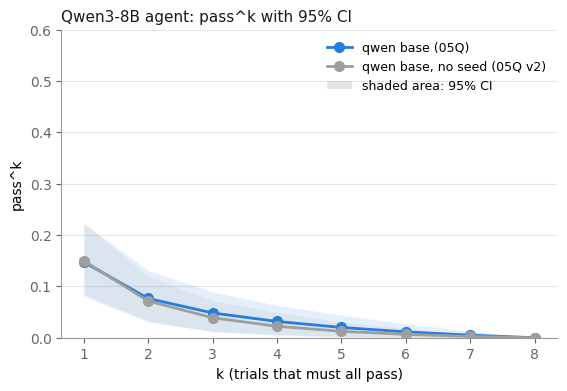

In [17]:
# Why: pass^k (k = 1..8) with 95% CI is the headline metric. The comparison lines of cell 3 (and the
# first, unseeded run in grey) are drawn in the same chart. ylim stays fixed at 0.6 so every Qwen
# notebook draws on the same axis (H7). Only this arm's csv and figure are written.
import csv, matplotlib.pyplot as plt
from matplotlib.patches import Patch
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS
          if os.path.isdir(f"{ROOT}/{d}")}             # a missing line is skipped
show(pd.DataFrame([{"arm": n, **{f"k={r['k']}": f"{r['pass^k']:.3f}" for r in rows},
                    "95% CI k=1": f"[{rows[0]['ci_low']:.2f}, {rows[0]['ci_high']:.2f}]",
                    "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}" if rows[0]["pass^k"] else "-"}
                   for n, rows in curves.items() if rows]))
r = curves.get(ARMS[0][0])
if r:
    with open(f"{ROOT}/{OUT}_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=r[0].keys()); w.writeheader(); w.writerows(r)
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, d, color in ARMS:
    r = curves.get(name)
    if not r: continue
    ks = [x["k"] for x in r]
    ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], color=color, alpha=0.12, lw=0)
    ax.plot(ks, [x["pass^k"] for x in r], "-", marker="o", ms=7, lw=2, color=color, label=name)
ax.set(xlabel="k (trials that must all pass)", ylabel="pass^k", ylim=(0, 0.6), xticks=range(1, 9))
ax.set_title("Qwen3-8B agent: pass^k with 95% CI", loc="left", fontsize=11, color="#191919")
ax.spines[["top", "right"]].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#999999")
ax.tick_params(colors="#666666"); ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#999999", alpha=0.25, label="shaded area: 95% CI"))
ax.legend(handles=handles, frameon=False, fontsize=9)
os.makedirs(f"{ROOT}/figures", exist_ok=True)
plt.savefig(f"{ROOT}/figures/{OUT}_passk.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
# Why: paired comparisons over the same tasks: per task, pass^k = C(c, k) / C(8, k) (c = passes in
# 8 trials), then the mean difference with a 95% bootstrap CI over tasks (10,000 resamples, fixed seed).
# Shown for all 50 tasks and for the 42 clean tasks (8 tasks have answer keys that break the policy).
# The seed check (seeded − unseeded run of the same arm) should not be significant: if it is, the
# seeds changed the result, and the report must say so. One csv per comparison, for 10Q.
import numpy as np
from math import comb
BAD_KEYS = {10, 16, 19, 26, 27, 34, 45, 46}         # answer keys that break the policy (Part 1, 06G)
KS = [1, 2, 4, 8]

def per_task(folder):
    full = {t: v for t, v in tab_of(folder).items() if len(v) == N_TASKS}
    assert len(full) == N_TRIALS, f"{folder}: {len(full)} of {N_TRIALS} trials complete"
    c = passk.success_counts(full, range(N_TASKS))
    return {k: np.array([comb(c[t], k) / comb(N_TRIALS, k) for t in range(N_TASKS)]) for k in KS}

def paired(a, b, tasks, n=10_000, seed=691):
    d = a[tasks] - b[tasks]
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return d.mean(), lo, hi

me = per_task(OUT)
TASKS = [("all 50", np.arange(N_TASKS)),
         ("clean 42", np.array([t for t in range(N_TASKS) if t not in BAD_KEYS]))]
for ref_name, ref_out, tag in COMPARE:
    if not os.path.isdir(f"{ROOT}/{ref_out}"):
        print(f"{ARM} − {ref_name}: {ref_out} not found, skipped"); continue
    ref = per_task(ref_out)
    rows = []
    for name, tasks in TASKS:
        for k in KS:
            m, lo, hi = paired(me[k], ref[k], tasks)
            rows.append({"tasks": name, "k": k, ARM: f"{me[k][tasks].mean():.3f}",
                         ref_name: f"{ref[k][tasks].mean():.3f}", f"Δ ({ARM} − {ref_name})": f"{m:+.3f}",
                         "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "significant": "*" if lo > 0 or hi < 0 else ""})
    df = pd.DataFrame(rows)
    df.to_csv(f"{ROOT}/{OUT}_{tag}.csv", index=False)
    print(f"{ARM} − {ref_name}")
    show(df)

base − base no seed


tasks,k,base,base no seed,Δ (base − base no seed),95% CI,significant
all 50,1,0.147,0.150,-0.003,"[-0.048, +0.045]",
all 50,2,0.076,0.071,+0.005,"[-0.031, +0.045]",
all 50,4,0.032,0.022,+0.009,"[-0.009, +0.035]",
all 50,8,0.000,0.000,+0.000,"[+0.000, +0.000]",
clean 42,1,0.176,0.179,-0.003,"[-0.060, +0.054]",
clean 42,2,0.091,0.085,+0.006,"[-0.038, +0.054]",
clean 42,4,0.038,0.027,+0.011,"[-0.011, +0.041]",
clean 42,8,0.000,0.000,+0.000,"[+0.000, +0.000]",


In [19]:
# Why: the brief's metrics, for this arm, the validator (06Q) and the baseline (05Q), from the saved
# dialogues: "Policy-violation rate, split into three types", "Violation rate by turn position
# (early, middle, late)", and "Violations on tasks that still pass on final state".
#  Type 1, illegal tool calls: rule-breaking write calls that really ran (06G's checker, replayed on
#          a fresh database copy). Blocked calls are counted apart: they never reached the database.
#  Type 2, dialogue-level violations (all executed calls; proxies, checked by hand in 07Q-09Q):
#    - skipped confirmation (G1): a booking / change ran although the user's last message had no yes
#    - skipped explanation (G1 "list the action details"): the agent did not state the reservation id
#      and the new flights / bag count / passenger names to the user before the call. Writes made
#      after one user message share one explanation (hand-check fix: a batched change was explained
#      once, then counted as unexplained for the second call).
#    - tool call and reply in the same turn (G3)
#    - forbidden statement (G2 "no subjective recommendations"): phrases like "I recommend",
#      "you should go with", "the best option is"
#  Type 3, reasoning / argument errors: write calls the database rejected; any tool call that came
#          back as an error; malformed calls (arguments not JSON, or a tool that does not exist).
# Position = message index / dialogue length, cut in thirds. Rates are per 100 dialogues.
# The first table keeps the exact columns of 05Q / 06Q, so the numbers can be checked against them.
# Only this arm's json is saved for 10Q; 05Q's and 06Q's files are never touched.
import json, re, time, importlib, violations as V, policy_checker as pc
importlib.reload(V); importlib.reload(pc)
from tau_bench.envs.airline.data import load_data
graph = pc.load_graph()
YES = re.compile(r"\b(yes|yeah|yep|yup|confirm(ed)?|go ahead|proceed|sure|please do|do it|sounds good|"
                 r"that'?s (fine|correct|right)|ok(ay)?|correct)\b", re.I)
RECO = re.compile(r"\b(i (would |'d )?(recommend|suggest)|my (recommendation|suggestion) (is|would be)|"
                  r"i think you should|you should (choose|go with|book|pick|take)|"
                  r"the best (option|choice|deal) (is|would be|for you)|i('d| would) go with)\b", re.I)
G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}
TYPES = [("illegal", "1 · illegal tool call that ran"),
         ("g1_no_yes", "2 · skipped confirmation (G1)"),
         ("no_explain", "2 · skipped explanation (G1)"),
         ("g3_call_and_reply", "2 · tool call + reply in one turn (G3)"),
         ("g2_recommend", "2 · forbidden statement: recommendation (G2)"),
         ("db_rejected", "3 · write call rejected by the database"),
         ("tool_error", "3 · any tool call that returned an error"),
         ("malformed", "3 · malformed call (bad JSON / unknown tool)")]

def details(name, kw):
    # the values the agent must state before the call (G1: "list the action details")
    flights = [f.get("flight_number") for f in kw.get("flights") or [] if isinstance(f, dict)]
    rid = [kw.get("reservation_id")]
    return [v for v in {"book_reservation": flights,
                        "update_reservation_flights": rid + flights,
                        "update_reservation_baggages": rid + [kw.get("total_baggages")],
                        "update_reservation_passengers": rid + [p.get("first_name") for p in kw.get("passengers") or []
                                                                if isinstance(p, dict)]}.get(name, [])
            if v not in (None, "")]

def scan(traj):
    # replay like violations.py, keeping the position of every violation in the dialogue
    traj = [m for m in traj if isinstance(m, dict)]
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, last_user, said, wrote = load_data(), [], "", "", False
    pos = lambda i: i / max(len(traj) - 1, 1)
    out = {k: [] for k, _ in TYPES}
    out.update(blocked=0, g1_calls=0)
    for i, m in enumerate(traj):
        if m.get("role") == "user":
            last_user = m.get("content") or ""
            if wrote: said, wrote = "", False                    # a new request: explain again
        if m.get("role") != "assistant":
            continue
        text = (m.get("content") or "").strip()
        said += " " + text.lower()
        if text and m.get("tool_calls"): out["g3_call_and_reply"].append(pos(i))
        if RECO.search(text): out["g2_recommend"].append(pos(i))
        for c in m.get("tool_calls") or []:
            name = c["function"]["name"]
            try: kw = json.loads(c["function"]["arguments"] or "{}")
            except json.JSONDecodeError: kw = None
            if name not in V.TOOLS or not isinstance(kw, dict):
                out["malformed"].append(pos(i)); continue
            if c["id"] not in obs: continue
            o = str(obs[c["id"]]); blocked = o.startswith(V.BLOCK_TAG)
            if blocked:
                out["blocked"] += name in pc.WRITE_TOOLS; continue
            if o.startswith("Error"): out["tool_error"].append(pos(i))
            if name in pc.WRITE_TOOLS:
                if pc.check(name, kw, data, hist, graph): out["illegal"].append(pos(i))
                if o.startswith("Error"): out["db_rejected"].append(pos(i))
                if name in G1_TOOLS:
                    out["g1_calls"] += 1
                    if not YES.search(last_user): out["g1_no_yes"].append(pos(i))
                    if not all(str(v).lower() in said for v in details(name, kw)): out["no_explain"].append(pos(i))
            try: res = V.TOOLS[name].invoke(data=data, **kw)
            except Exception as e: res = f"Error: {e}"
            if name in pc.WRITE_TOOLS and not str(res).startswith("Error"):
                hist.append({"name": name, "kwargs": kw}); wrote = True
    return out

third = lambda p: "early" if p < 1 / 3 else "middle" if p < 2 / 3 else "late"
compat, long_rows, t0 = [], [], time.time()
for name, d, _ in ARMS:
    if not os.path.isdir(f"{ROOT}/{d}"): continue   # a missing line is skipped
    n = npass = 0
    tot = {k: {"count": 0, "early": 0, "middle": 0, "late": 0, "passing dialogues with it": 0} for k, _ in TYPES}
    blocked = g1_calls = 0
    for tasks in tab_of(d).values():
        for r in tasks.values():
            s = scan(r.get("traj") or [])
            n += 1; ok = r["reward"] >= 1 - 1e-6; npass += ok
            blocked += s["blocked"]; g1_calls += s["g1_calls"]
            for k, _ in TYPES:
                tot[k]["count"] += len(s[k])
                for p in s[k]: tot[k][third(p)] += 1
                tot[k]["passing dialogues with it"] += ok and len(s[k]) > 0
    i, g = tot["illegal"], tot["g1_no_yes"]
    compat.append({"arm": name, "blocked calls": blocked, "illegal calls run": i["count"],
                   "early / middle / late": f'{i["early"]} / {i["middle"]} / {i["late"]}',
                   "G1: write without a yes": f'{g["count"]}/{g1_calls}',
                   "argument errors": tot["db_rejected"]["count"],
                   "passing dialogues with a violation": f'{i["passing dialogues with it"]}/{npass}'})
    for k, label in TYPES:
        t = tot[k]
        long_rows.append({"type": label, "arm": name, "count": t["count"], "per 100 dialogues": f'{100 * t["count"] / max(n, 1):.1f}',
                          "early / middle / late": f'{t["early"]} / {t["middle"]} / {t["late"]}',
                          "passing dialogues with it": f'{t["passing dialogues with it"]}/{npass}'})
    if d == OUT:
        json.dump({"dialogues": n, "passed": npass, "blocked": blocked, "g1_calls": g1_calls, "types": tot,
                   # the 05Q / 06Q keys, for 10Q
                   "illegal": i["count"], "g1_miss": g["count"], "arg_err": tot["db_rejected"]["count"],
                   "early": i["early"], "middle": i["middle"], "late": i["late"], "passed dialogues": npass,
                   "passed with ≥1 illegal": i["passing dialogues with it"]},
                  open(f"{ROOT}/{OUT}_violations.json", "w"), indent=2)
print("Same columns as 05Q / 06Q (check against them):")
show(pd.DataFrame(compat))
print("All violation types (brief: three types, by turn position, on passing dialogues):")
order = {label: j for j, (_, label) in enumerate(TYPES)}
show(pd.DataFrame(long_rows).sort_values("type", key=lambda s: s.map(order), kind="stable"))
print(f"scanned in {time.time() - t0:.0f} s; saved {OUT}_violations.json")

Same columns as 05Q / 06Q (check against them):


arm,blocked calls,illegal calls run,early / middle / late,G1: write without a yes,argument errors,passing dialogues with a violation
qwen base (05Q),0,363,95 / 122 / 146,359/598,258,3/59
"qwen base, no seed (05Q v2)",0,339,86 / 90 / 163,342/571,229,5/60


All violation types (brief: three types, by turn position, on passing dialogues):


type,arm,count,per 100 dialogues,early / middle / late,passing dialogues with it
1 · illegal tool call that ran,qwen base (05Q),363,90.8,95 / 122 / 146,3/59
1 · illegal tool call that ran,"qwen base, no seed (05Q v2)",339,84.8,86 / 90 / 163,5/60
2 · skipped confirmation (G1),qwen base (05Q),359,89.8,58 / 159 / 142,14/59
2 · skipped confirmation (G1),"qwen base, no seed (05Q v2)",342,85.5,55 / 137 / 150,11/60
2 · skipped explanation (G1),qwen base (05Q),390,97.5,43 / 140 / 207,15/59
2 · skipped explanation (G1),"qwen base, no seed (05Q v2)",356,89.0,54 / 134 / 168,13/60
2 · tool call + reply in one turn (G3),qwen base (05Q),11,2.8,0 / 3 / 8,5/59
2 · tool call + reply in one turn (G3),"qwen base, no seed (05Q v2)",17,4.2,3 / 4 / 10,6/60
2 · forbidden statement: recommendation (G2),qwen base (05Q),49,12.2,5 / 6 / 38,8/59
2 · forbidden statement: recommendation (G2),"qwen base, no seed (05Q v2)",80,20.0,4 / 21 / 55,10/60


scanned in 46 s; saved results_qwen_base_violations.json


In [20]:
# Why: which tasks each arm solves every time, never, or only sometimes; the unseeded run shows how
# much these counts move between two runs of the same arm. Only this arm's json is saved.
cons = {}
for name, d, _ in ARMS:
    if not os.path.isdir(f"{ROOT}/{d}"): continue   # a missing line is skipped
    full = {t: v for t, v in tab_of(d).items() if len(v) == N_TASKS}
    c = passk.success_counts(full, range(N_TASKS))
    cons[name] = {"always pass": len([t for t in c if c[t] == N_TRIALS]),
                  "sometimes": len([t for t in c if 0 < c[t] < N_TRIALS]),
                  "never pass": len([t for t in c if c[t] == 0])}
json.dump(cons[ARMS[0][0]], open(f"{ROOT}/{OUT}_consistency.json", "w"), indent=2)
show(pd.DataFrame(cons).rename_axis("type").reset_index())

type,qwen base (05Q),"qwen base, no seed (05Q v2)"
always pass,0,0
sometimes,18,18
never pass,32,32


## Summary

**Run:** L4 (22 GB), vLLM 0.34.0, 24k context (full setting 32k; note in the report), max-num-seqs 8, 50 tasks × 8 trials, simulator seed = trial number. 400/400 done, 0 API errors, no checklist in any prompt, 2,845 seeded user calls. Full run about 2.5 h, about $1 for the Gemini user simulator. Seed check (cell 8): Gemini accepts seed: yes; same seed repeats the reply: yes; seed 2 gives another reply: yes. Passed per trial: 7 / 13 / 8 / 5 / 6 / 5 / 9 / 6.

**Run note:** trial 1 ran in two parts (16 + 34 tasks) because the Colab session stopped. Both parts used simulator seed 1 and the same settings. The runner skips finished tasks, so no task ran twice. The first 16 dialogues had 0 API errors.

| | pass^1 (95% CI) | pass^8 | drop 1→8 | illegal calls run | G1: write without a yes | passing with a violation |
|---|---|---|---|---|---|---|
| **Qwen base, seeded** | 0.147 [0.08, 0.22] | 0.000 | 100% | 363 | 359/598 | 3/59 |
| Qwen base, no seed (v2) | 0.150 [0.09, 0.22] | 0.000 | 100% | 339 | 342/571 | 5/60 |

**Seed check (cell 12):** seeded − unseeded: Δpass^1 = −0.003 [−0.048, +0.045], Δpass^8 = +0.000; clean 42: −0.003 [−0.060, +0.054]. Not significant at any k. Adding simulator seeds did not change the baseline.

**Violations by type (cell 13, per 100 dialogues; counts early / middle / late):**
- Type 1, illegal calls: 90.8 (95 / 122 / 146); no seed 84.8.
- Type 2: skipped confirmation 89.8 (58 / 159 / 142), skipped explanation 97.5 (43 / 140 / 207), call + reply 2.8 (0 / 3 / 8), recommendation 12.2 (5 / 6 / 38). No seed: 85.5 / 89.0 / 4.2 / 20.0.
- Type 3: database-rejected 64.5 (40 / 110 / 108), tool errors 106.5 (165 / 133 / 128), malformed 4.8 (5 / 10 / 4). No seed: 57.2 / 93.8 / 1.8.
- The seeded run made a few more writes (598 vs 571), so it has a few more illegal and rejected calls; the share of writes without a yes is the same (60%). These are normal run-to-run differences.

**Consistency (cell 14):** always / sometimes / never pass: 0 / 18 / 32 (no seed: 0 / 18 / 32, the same).

**Takeaway:** the seeded baseline is the same as the unseeded one: same pass^1, same pass^k curve, same task split. The baseline never solves a task every time. All five systems are now compared with this seeded run.

**Next:** 06Q, seeded rerun; then rerun 07Q cells 3, 9–15.